# Stage 2: Human Pose Estimation

## Objectives

- Understand human pose estimation and keypoint representations.
- Run a pretrained pose-estimation model.
- Predict 17 human body keypoints.
- Understand normalized coordinates and confidence scores.
- Visualize predicted keypoints and the human skeleton.
- Apply pose estimation to a walking video.
- Save predictions for subsequent gait-analysis experiments.

## Dataset

Input video: `data/raw/sample_walking.mp4`

## Planned Model

MoveNet Lightning — single-person human pose estimation.

## Important Note

Stage 1 used hypothetical keypoints to practice coordinate mapping.
Stage 2 will use actual model predictions.

In [39]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

project_root = Path.cwd()

video_path = project_root / ".." / "data" / "raw" / "sample_walking.mp4"

print("Working directory:", project_root)
print("Video exists:", video_path.exists())

if video_path.exists():
    cap = cv2.VideoCapture(str(video_path))

    print("Video opened:", cap.isOpened())
    print("FPS:", cap.get(cv2.CAP_PROP_FPS))
    print("Frame count:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))

    cap.release()

Working directory: /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/notebooks
Video exists: True
Video opened: True
FPS: 29.97002997002997
Frame count: 405


In [40]:
from pathlib import Path
import sys

current_dir = Path.cwd().resolve()

project_root = next(
    (
        directory
        for directory in [current_dir, *current_dir.parents]
        if (directory / "pyproject.toml").exists()
    ),
    None,
)

if project_root is None:
    raise RuntimeError("Could not locate the project root.")

video_path = project_root / "data" / "raw" / "sample_walking.mp4"

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Project root:", project_root)
print("Video exists:", video_path.exists())

Python executable: /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab/.venv/bin/python
Python version: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
Project root: /home/aghammd/Desktop/Programming/markerless-pose-estimation-lab
Video exists: True


In [41]:
from ai_edge_litert.interpreter import Interpreter

model_path = project_root / "models" / "movenet_lightning.tflite"

if not model_path.exists():
    raise FileNotFoundError(f"Model not found: {model_path}")

interpreter = Interpreter(
    model_path=str(model_path),
    num_threads=4,
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Model loaded successfully!")
print("\nInput details:")
for item in input_details:
    print({
        "shape": item["shape"].tolist(),
        "dtype": str(item["dtype"]),
        "name": item["name"],
    })

print("\nOutput details:")
for item in output_details:
    print({
        "shape": item["shape"].tolist(),
        "dtype": str(item["dtype"]),
        "name": item["name"],
    })

Model loaded successfully!

Input details:
{'shape': [1, 192, 192, 3], 'dtype': "<class 'numpy.uint8'>", 'name': 'serving_default_input:0'}

Output details:
{'shape': [1, 1, 17, 3], 'dtype': "<class 'numpy.float32'>", 'name': 'StatefulPartitionedCall:0'}


In [42]:
print("INPUT DETAILS")
for item in input_details:
    print(item)

print("\nOUTPUT DETAILS")
for item in output_details:
    print(item)

INPUT DETAILS
{'name': 'serving_default_input:0', 'index': 0, 'shape': array([  1, 192, 192,   3], dtype=int32), 'shape_signature': array([  1, 192, 192,   3], dtype=int32), 'dtype': <class 'numpy.uint8'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}

OUTPUT DETAILS
{'name': 'StatefulPartitionedCall:0', 'index': 316, 'shape': array([ 1,  1, 17,  3], dtype=int32), 'shape_signature': array([ 1,  1, 17,  3], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}


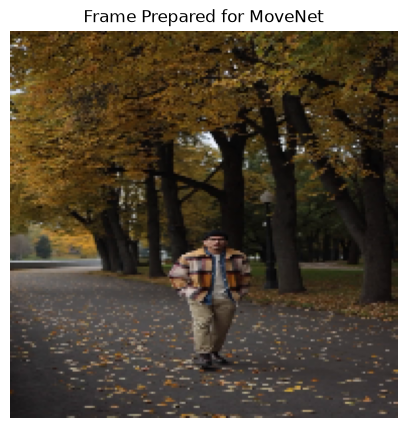

Original frame: (1920, 1080, 3)
Model input image: (192, 192, 3)
Expected model input shape: [  1 192 192   3]


In [43]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise RuntimeError(f"Failed to open video: {video_path}")

ret, frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError("Failed to read a frame from the video.")

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


input_shape = input_details[0]["shape"]
input_height, input_width = int(input_shape[1]), int(input_shape[2])

resized_frame = cv2.resize(
    frame_rgb, (input_width, input_height)
)

plt.figure(figsize=(5, 7))
plt.imshow(resized_frame)
plt.title("Frame Prepared for MoveNet")
plt.axis("off")
plt.show()

print("Original frame:", frame.shape)
print("Model input image:", resized_frame.shape)
print("Expected model input shape:", input_shape)

In [44]:
input_dtype = input_details[0]["dtype"]

# Add a batch dimension: (H, W, C) -> (1, H, W, C)
model_input = np.expand_dims(resized_frame, axis=0)

if input_dtype == np.uint8:
    model_input = model_input.astype(np.uint8)
elif input_dtype == np.float32:
    model_input = model_input.astype(np.float32)
else:
    raise TypeError(f"Unexpected model input dtype: {input_dtype}")

interpreter.set_tensor(
    input_details[0]["index"],
    model_input,
)

interpreter.invoke()

raw_output = interpreter.get_tensor(
    output_details[0]["index"]
)

keypoints = np.squeeze(raw_output)

print("Raw output shape:", raw_output.shape)
print("Keypoints shape:", keypoints.shape)

if keypoints.shape != (17, 3):
    raise ValueError(
        f"Expected 17 keypoints with 3 values each, "
        f"but received {keypoints.shape}"
    )

print("\nFirst five keypoints:")
for index, (y, x, score) in enumerate(keypoints[:5]):
    print(
        f"Keypoint {index}: "
        f"y={y:.4f}, x={x:.4f}, confidence={score:.4f}"
    )

Raw output shape: (1, 1, 17, 3)
Keypoints shape: (17, 3)

First five keypoints:
Keypoint 0: y=0.5516, x=0.5345, confidence=0.3566
Keypoint 1: y=0.5437, x=0.5424, confidence=0.4331
Keypoint 2: y=0.5404, x=0.5271, confidence=0.4871
Keypoint 3: y=0.5394, x=0.5517, confidence=0.3587
Keypoint 4: y=0.5374, x=0.5129, confidence=0.5249


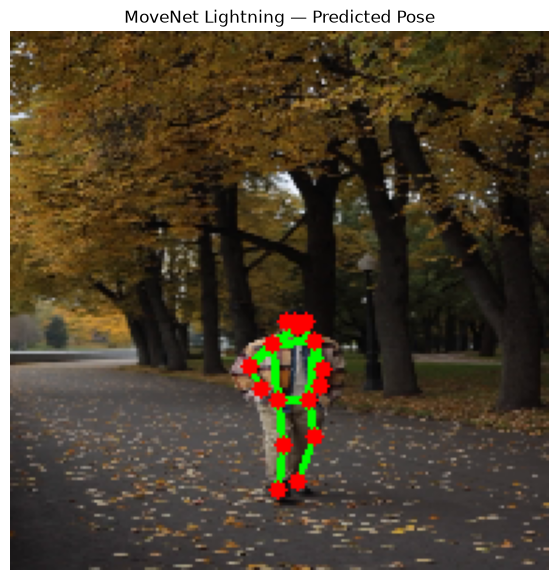

In [45]:
# MoveNet keypoint indices
KEYPOINT_NAMES = [
    "nose",
    "left_eye",
    "right_eye",
    "left_ear",
    "right_ear",
    "left_shoulder",
    "right_shoulder",
    "left_elbow",
    "right_elbow",
    "left_wrist",
    "right_wrist",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_ankle",
    "right_ankle",
]

# Pairs of keypoints to connect
SKELETON_EDGES = [
    (0, 1), (0, 2),
    (1, 3), (2, 4),
    (0, 5), (0, 6),
    (5, 7), (7, 9),
    (6, 8), (8, 10),
    (5, 6),
    (5, 11), (6, 12),
    (11, 12),
    (11, 13), (13, 15),
    (12, 14), (14, 16),
]

confidence_threshold = 0.2

# Draw on the resized RGB image used for inference.
annotated_image = resized_frame.copy()

image_height, image_width = annotated_image.shape[:2]

# Convert normalized coordinates into pixel coordinates.
keypoint_pixels = []

for y, x, score in keypoints:
    x_pixel = int(x * image_width)
    y_pixel = int(y * image_height)

    keypoint_pixels.append((x_pixel, y_pixel, float(score)))

# Draw skeleton connections.
for start_idx, end_idx in SKELETON_EDGES:
    x1, y1, score1 = keypoint_pixels[start_idx]
    x2, y2, score2 = keypoint_pixels[end_idx]

    if (
        score1 >= confidence_threshold
        and score2 >= confidence_threshold
    ):
        cv2.line(
            annotated_image,
            (x1, y1),
            (x2, y2),
            color=(0, 255, 0),
            thickness=2,
        )

# Draw keypoints.
for idx, (x_pixel, y_pixel, score) in enumerate(keypoint_pixels):
    if score >= confidence_threshold:
        cv2.circle(
            annotated_image,
            (x_pixel, y_pixel),
            radius=3,
            color=(255, 0, 0),
            thickness=-1,
        )

plt.figure(figsize=(7, 7))
plt.imshow(annotated_image)
plt.title("MoveNet Lightning — Predicted Pose")
plt.axis("off")
plt.show()

In [46]:
for index, keypoint in enumerate(keypoints):
    confidence = keypoint[2]
    name = KEYPOINT_NAMES[index]

    print(f"{name:15s} confidence = {confidence:.3f}")

nose            confidence = 0.357
left_eye        confidence = 0.433
right_eye       confidence = 0.487
left_ear        confidence = 0.359
right_ear       confidence = 0.525
left_shoulder   confidence = 0.399
right_shoulder  confidence = 0.482
left_elbow      confidence = 0.403
right_elbow     confidence = 0.377
left_wrist      confidence = 0.296
right_wrist     confidence = 0.387
left_hip        confidence = 0.514
right_hip       confidence = 0.369
left_knee       confidence = 0.469
right_knee      confidence = 0.269
left_ankle      confidence = 0.373
right_ankle     confidence = 0.302


In [47]:
def predict_pose(frame):
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    input_shape = input_details[0]["shape"]
    input_height, input_width = int(input_shape[1]), int(input_shape[2])

    resized_frame = cv2.resize(
        frame_rgb,
        (input_width, input_height)
    )

    model_input = np.expand_dims(resized_frame, axis=0)

    input_dtype = input_details[0]["dtype"]

    if input_dtype == np.uint8:
        model_input = model_input.astype(np.uint8)
    elif input_dtype == np.float32:
        model_input = model_input.astype(np.float32)
    else:
        raise TypeError(f"Unsupported input dtype: {input_dtype}")

    interpreter.set_tensor(
        input_details[0]["index"],
        model_input
    )

    interpreter.invoke()

    raw_output = interpreter.get_tensor(
        output_details[0]["index"]
    )

    return np.squeeze(raw_output)

In [48]:
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise RuntimeError("Could not open video.")

all_keypoints = []
frame_indices = []

frame_index = 0
frame_step = 10

while True:
    ret, frame = cap.read()

    if not ret:
        break

    if frame_index % frame_step == 0:
        keypoints = predict_pose(frame)

        all_keypoints.append(keypoints)
        frame_indices.append(frame_index)

    frame_index += 1

cap.release()

all_keypoints = np.array(all_keypoints)
frame_indices = np.array(frame_indices)

print("Processed frames:", len(frame_indices))
print("Keypoints array shape:", all_keypoints.shape)
print("Frame indices:", frame_indices)

Processed frames: 41
Keypoints array shape: (41, 17, 3)
Frame indices: [  0  10  20  30  40  50  60  70  80  90 100 110 120 130 140 150 160 170
 180 190 200 210 220 230 240 250 260 270 280 290 300 310 320 330 340 350
 360 370 380 390 400]


In [49]:
left_knee = all_keypoints[:, 13, :]

print("Left knee array shape:", left_knee.shape)
print("\nFirst five predictions:")
print(left_knee[:5])

Left knee array shape: (41, 3)

First five predictions:
[[0.75177985 0.56272537 0.46920127]
 [0.7608885  0.5571371  0.38716272]
 [0.75590223 0.5704904  0.35360813]
 [0.7660895  0.59789836 0.38747603]
 [0.7657022  0.6142333  0.41117522]]


In [50]:
left_knee_y = left_knee[:, 0]
left_knee_x = left_knee[:, 1]
left_knee_confidence = left_knee[:, 2]

print("Vertical coordinates:", left_knee_y[:5])
print("Horizontal coordinates:", left_knee_x[:5])
print("Confidence scores:", left_knee_confidence[:5])

Vertical coordinates: [0.75177985 0.7608885  0.75590223 0.7660895  0.7657022 ]
Horizontal coordinates: [0.56272537 0.5571371  0.5704904  0.59789836 0.6142333 ]
Confidence scores: [0.46920127 0.38716272 0.35360813 0.38747603 0.41117522]


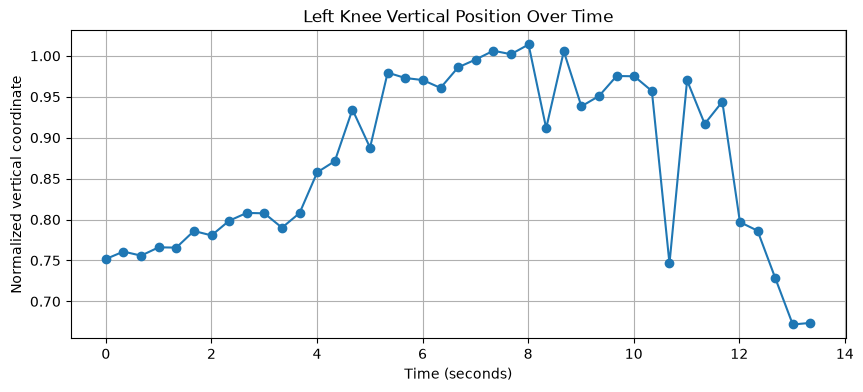

In [51]:
import matplotlib.pyplot as plt

fps = 29.97002997

time_seconds = frame_indices / fps

plt.figure(figsize=(10, 4))

plt.plot(time_seconds, left_knee_y, marker="o")

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized vertical coordinate")
plt.title("Left Knee Vertical Position Over Time")

plt.grid(True)
plt.show()

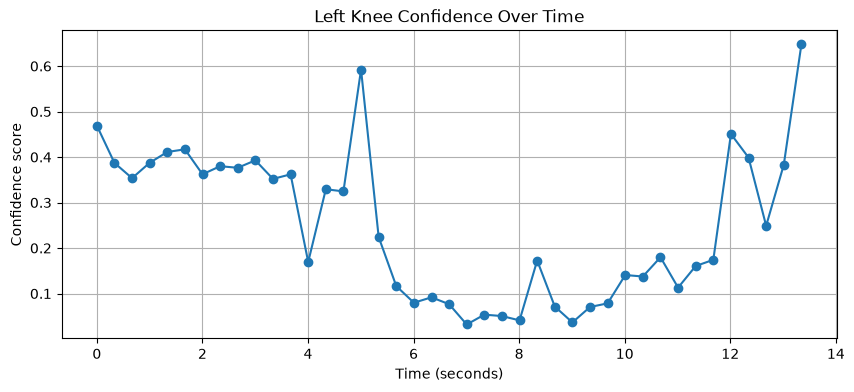

In [52]:
plt.figure(figsize=(10, 4))

plt.plot(
    time_seconds,
    left_knee_confidence,
    marker="o"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Confidence score")
plt.title("Left Knee Confidence Over Time")
plt.grid(True)

plt.show()

In [53]:
left_knee_y_change = np.diff(left_knee_y)

print("Shape:", left_knee_y_change.shape)
print("First 10 vertical changes:")
print(left_knee_y_change[:10])

Shape: (40,)
First 10 vertical changes:
[ 0.00910866 -0.00498629  0.01018727 -0.00038731  0.02033961 -0.0054096
  0.01789689  0.00958228 -0.00050044 -0.01757342]


In [54]:
largest_change_index = np.argmax(np.abs(left_knee_y_change))

print("Index of largest change:", largest_change_index)
print("Vertical change:", left_knee_y_change[largest_change_index])

print(
    "Time before change:",
    time_seconds[largest_change_index]
)

print(
    "Time after change:",
    time_seconds[largest_change_index + 1]
)

Index of largest change: 32
Vertical change: 0.22366047
Time before change: 10.677333333344011
Time after change: 11.01100000001101


In [55]:
i = largest_change_index

print("Prediction before the jump:")
print("Time:", time_seconds[i])
print("Y coordinate:", left_knee_y[i])
print("X coordinate:", left_knee_x[i])
print("Confidence:", left_knee_confidence[i])

print("\nPrediction after the jump:")
print("Time:", time_seconds[i + 1])
print("Y coordinate:", left_knee_y[i + 1])
print("X coordinate:", left_knee_x[i + 1])
print("Confidence:", left_knee_confidence[i + 1])

Prediction before the jump:
Time: 10.677333333344011
Y coordinate: 0.74632746
X coordinate: 0.5694368
Confidence: 0.17980798

Prediction after the jump:
Time: 11.01100000001101
Y coordinate: 0.9699879
X coordinate: 0.47428423
Confidence: 0.113048084


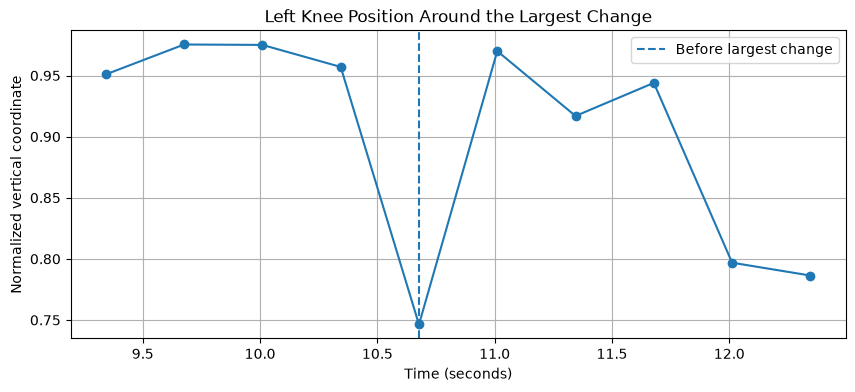

In [56]:
start = max(0, i - 4)
end = min(len(time_seconds), i + 6)

plt.figure(figsize=(10, 4))

plt.plot(
    time_seconds[start:end],
    left_knee_y[start:end],
    marker="o"
)

plt.axvline(
    time_seconds[i],
    linestyle="--",
    label="Before largest change"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized vertical coordinate")
plt.title("Left Knee Position Around the Largest Change")
plt.grid(True)
plt.legend()
plt.show()

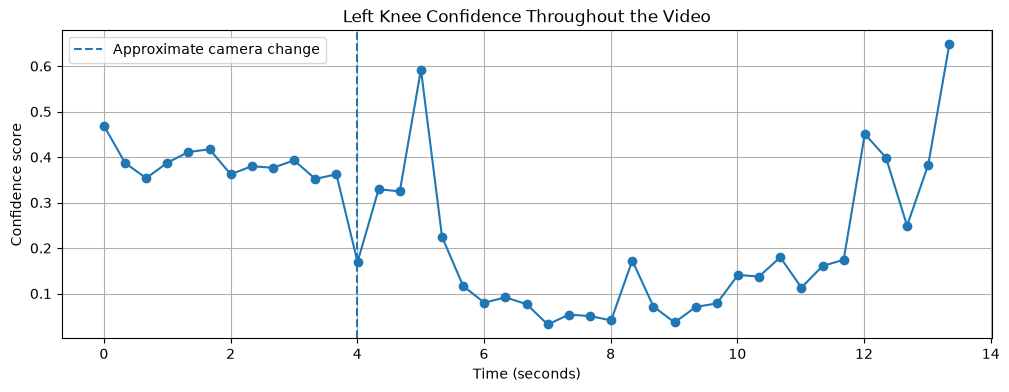

In [57]:
plt.figure(figsize=(12, 4))

plt.plot(
    time_seconds,
    left_knee_confidence,
    marker="o"
)

plt.axvline(
    4.0,
    linestyle="--",
    label="Approximate camera change"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Confidence score")
plt.title("Left Knee Confidence Throughout the Video")
plt.grid(True)
plt.legend()
plt.show()

In [58]:
confidence_threshold = 0.3

left_knee_reliable = (
    left_knee_confidence >= confidence_threshold
)

print("Total predictions:", len(left_knee_confidence))
print("Above threshold:", np.sum(left_knee_reliable))
print("Below threshold:", np.sum(~left_knee_reliable))

Total predictions: 41
Above threshold: 19
Below threshold: 22


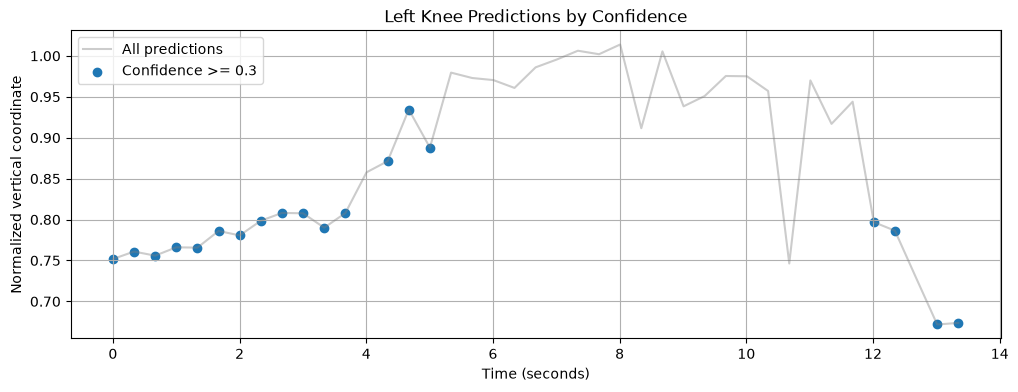

In [59]:
plt.figure(figsize=(12, 4))

plt.plot(
    time_seconds,
    left_knee_y,
    color="gray",
    alpha=0.4,
    label="All predictions"
)

plt.scatter(
    time_seconds[left_knee_reliable],
    left_knee_y[left_knee_reliable],
    label="Confidence >= 0.3"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized vertical coordinate")
plt.title("Left Knee Predictions by Confidence")
plt.grid(True)
plt.legend()
plt.show()

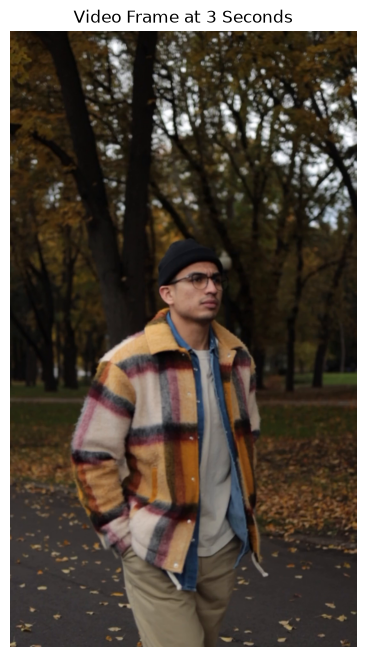

In [60]:
cap = cv2.VideoCapture(str(video_path))

cap.set(cv2.CAP_PROP_POS_MSEC, 6_000)
ret, frame = cap.read()

cap.release()

if not ret:
    raise RuntimeError("Could not read the frame.")

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 8))
plt.imshow(frame_rgb)
plt.title("Video Frame at 3 Seconds")
plt.axis("off")
plt.show()

In [61]:
visible_period = time_seconds <= 4.0

print("Total sampled frames:", len(time_seconds))
print("Frames within first 4 seconds:", np.sum(visible_period))
print("Selected timestamps:", time_seconds[visible_period])

Total sampled frames: 41
Frames within first 4 seconds: 12
Selected timestamps: [0.         0.33366667 0.66733333 1.001      1.33466667 1.66833333
 2.002      2.33566667 2.66933333 3.003      3.33666667 3.67033333]


In [62]:
visible_time = time_seconds[visible_period]

visible_left_knee_y = left_knee_y[visible_period]
visible_left_knee_x = left_knee_x[visible_period]
visible_left_knee_confidence = left_knee_confidence[visible_period]

print("Selected knee coordinates:", visible_left_knee_y.shape)

Selected knee coordinates: (12,)


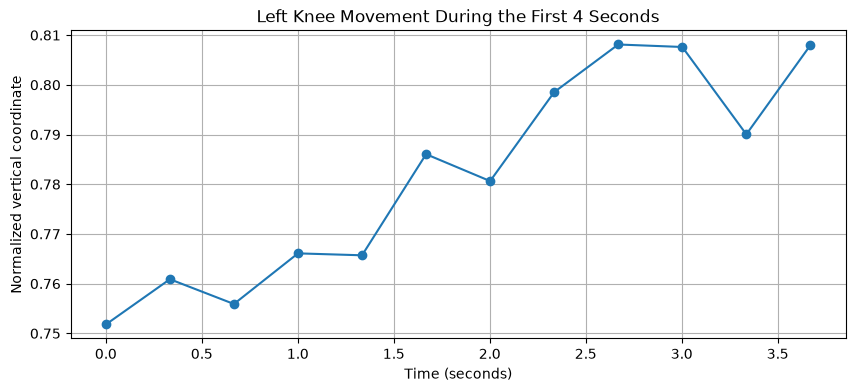

In [63]:
plt.figure(figsize=(10, 4))

plt.plot(
    visible_time,
    visible_left_knee_y,
    marker="o"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized vertical coordinate")
plt.title("Left Knee Movement During the First 4 Seconds")
plt.grid(True)
plt.show()

In [64]:
frame_position = np.where(visible_period)[0][0]

keypoints = all_keypoints[frame_position]

left_hip = keypoints[11]
left_knee_point = keypoints[13]
left_ankle = keypoints[15]

print("Left hip [y, x, confidence]:", left_hip)
print("Left knee [y, x, confidence]:", left_knee_point)
print("Left ankle [y, x, confidence]:", left_ankle)

Left hip [y, x, confidence]: [0.68562573 0.5529671  0.51400006]
Left knee [y, x, confidence]: [0.75177985 0.56272537 0.46920127]
Left ankle [y, x, confidence]: [0.83829635 0.53409106 0.37253687]


## 12.3 — Calculating the Knee Angle

We can estimate the 2D knee angle using three pose-estimation keypoints:
- Left hip
- Left knee
- Left ankle

The knee is the vertex of the angle. We construct two vectors originating at the knee:

$$
\vec{v}_1 = \text{Hip} - \text{Knee}
$$

$$
\vec{v}_2 = \text{Ankle} - \text{Knee}
$$

The angle between the vectors can be calculated using the dot product:

$$
\cos(\theta) =
\frac{\vec{v}_1 \cdot \vec{v}_2}
{\|\vec{v}_1\|\|\vec{v}_2\|}
$$

Therefore:

$$
\theta =
\cos^{-1}\left(
\frac{\vec{v}_1 \cdot \vec{v}_2}
{\|\vec{v}_1\|\|\vec{v}_2\|}
\right)
$$

We convert the result from radians to degrees.

**Interpretation:** The resulting angle is the geometric angle between the hip-to-knee and ankle-to-knee vectors. A nearly straight leg produces an angle close to 180°, while a more flexed knee produces a smaller angle.

This is an exploratory 2D estimate, not a validated clinical measurement.

In [65]:
# Convert [y, x] coordinates into conventional [x, y] coordinates
hip_xy = left_hip[:2][::-1]
knee_xy = left_knee_point[:2][::-1]
ankle_xy = left_ankle[:2][::-1]

# Construct vectors originating at the knee
vector_1 = hip_xy - knee_xy
vector_2 = ankle_xy - knee_xy

# Calculate the dot product
dot_product = np.dot(vector_1, vector_2)

# Calculate the product of the vector magnitudes
magnitude_product = (
    np.linalg.norm(vector_1) * np.linalg.norm(vector_2)
)

# Calculate the cosine of the angle
cos_theta = dot_product / magnitude_product

# Protect against floating-point rounding errors
cos_theta = np.clip(cos_theta, -1.0, 1.0)

# Calculate the angle in degrees
knee_angle = np.degrees(np.arccos(cos_theta))

print(f"Geometric knee angle: {knee_angle:.2f} degrees")

Geometric knee angle: 153.30 degrees


### 13. Reusable Joint-Angle Calculation

#### Objective
Implement a reusable function to calculate the 2D angle formed by three points: a starting point, a vertex, and an ending point. For knee-angle estimation, these points correspond to the hip, knee, and ankle.

#### Mathematical Formulation
Let the three points be $A$, $B$, and $C$, where $B$ is the vertex of the angle.

We construct two vectors:
$$\vec{BA} = A - B$$
$$\vec{BC} = C - B$$

Using the dot-product identity:
$$\vec{BA} \cdot \vec{BC} = |\vec{BA}| \, |\vec{BC}| \cos(\theta)$$

We obtain:
$$\theta = \cos^{-1}\left( \frac{\vec{BA} \cdot \vec{BC}}{|\vec{BA}| \, |\vec{BC}|} \right)$$

The angle is converted from radians to degrees.

#### Implementation Considerations
* Each point contains two coordinates: $x$ and $y$.
* The function should work for any three valid 2D points, not just knee coordinates.
* The cosine value must be clipped to the interval $[-1, 1]$ to account for floating-point rounding.
* If either vector has zero length, the angle is undefined and should not be calculated.
* The function returns the geometric angle in the range $0^\circ$ to $180^\circ$.

#### Limitation
This function calculates a 2D geometric angle. Its accuracy as a biomechanical joint-angle measurement depends on pose-estimation accuracy, camera perspective, visibility, and the suitability of the camera view.

In [66]:
def calculate_angle(point_a, point_b, point_c):
    """
    Calculate the 2D angle ABC in degrees.
    point_b is the vertex of the angle.
    """

    point_a = np.asarray(point_a, dtype=float)
    point_b = np.asarray(point_b, dtype=float)
    point_c = np.asarray(point_c, dtype=float)

    vector_1 = point_a - point_b
    vector_2 = point_c - point_b

    magnitude_1 = np.linalg.norm(vector_1)
    magnitude_2 = np.linalg.norm(vector_2)

    if magnitude_1 == 0 or magnitude_2 == 0:
        return np.nan

    cos_theta = np.dot(vector_1, vector_2) / (
        magnitude_1 * magnitude_2
    )

    cos_theta = np.clip(cos_theta, -1.0, 1.0)

    angle = np.degrees(np.arccos(cos_theta))

    return angle

In [67]:
# Case 1: A straight angle
angle_1 = calculate_angle(
    [0, 0],
    [1, 0],
    [2, 0]
)

# Case 2: A right angle
angle_2 = calculate_angle(
    [1, 0],
    [0, 0],
    [0, 1]
)

# Case 3: A 45-degree angle
angle_3 = calculate_angle(
    [1, 0],
    [0, 0],
    [1, 1]
)

print(f"Straight angle: {angle_1:.2f} degrees")
print(f"Right angle: {angle_2:.2f} degrees")
print(f"45-degree angle: {angle_3:.2f} degrees")

Straight angle: 180.00 degrees
Right angle: 90.00 degrees
45-degree angle: 45.00 degrees


In [68]:
# Convert [y, x, confidence] into [x, y]
hip_xy = left_hip[:2][::-1]
knee_xy = left_knee_point[:2][::-1]
ankle_xy = left_ankle[:2][::-1]

knee_angle = calculate_angle(
    hip_xy,
    knee_xy,
    ankle_xy
)

print(f"Geometric knee angle: {knee_angle:.2f} degrees")

Geometric knee angle: 153.30 degrees


### 14. Knee-Angle Estimation Across Multiple Frames

#### Objective
Calculate the left knee's geometric angle for each sampled frame during the first four seconds of the video and visualize how the angle changes over time.

#### Method
For each selected frame:
1. Extract the left hip, left knee, and left ankle keypoints.
2. Examine their confidence scores.
3. Exclude measurements when any of the three keypoints falls below the exploratory confidence threshold of $0.3$.
4. Convert normalized coordinates into image-pixel coordinates.
5. Calculate the angle using the reusable `calculate_angle()` function.
6. Plot the estimated angle against the corresponding timestamp.

#### Coordinate-System Consideration
The model outputs normalized coordinates, where $x$ and $y$ typically range from $0$ to $1$. Because the image width and height are different, directly calculating angles from normalized coordinates can distort the geometric angle.

We therefore convert coordinates using:
$$x_{\text{pixel}} = x_{\text{normalized}} \times W$$
$$y_{\text{pixel}} = y_{\text{normalized}} \times H$$

where $W$ and $H$ are the original image width and height.

#### Limitations
Confidence filtering does not guarantee that keypoints are visible or correctly localized. The resulting angles are exploratory 2D image-plane measurements, not validated anatomical joint angles.

In [69]:
cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise RuntimeError("Could not open video.")

image_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
image_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

cap.release()

print("Image width:", image_width)
print("Image height:", image_height)

Image width: 1080
Image height: 1920


In [70]:
confidence_threshold = 0.3

selected_positions = np.where(visible_period)[0]

knee_angles = []
knee_angle_times = []

for position in selected_positions:

    keypoints = all_keypoints[position]

    left_hip = keypoints[11]
    left_knee = keypoints[13]
    left_ankle = keypoints[15]

    # Check the confidence of all three keypoints
    confidences = [
        left_hip[2],
        left_knee[2],
        left_ankle[2]
    ]

    if min(confidences) < confidence_threshold:
        knee_angles.append(np.nan)
        knee_angle_times.append(time_seconds[position])
        continue

    # Convert normalized coordinates to pixel coordinates [x, y]
    hip_xy = np.array([
        left_hip[1] * image_width,
        left_hip[0] * image_height
    ])

    knee_xy = np.array([
        left_knee[1] * image_width,
        left_knee[0] * image_height
    ])

    ankle_xy = np.array([
        left_ankle[1] * image_width,
        left_ankle[0] * image_height
    ])

    angle = calculate_angle(
        hip_xy,
        knee_xy,
        ankle_xy
    )

    knee_angles.append(angle)
    knee_angle_times.append(time_seconds[position])

knee_angles = np.array(knee_angles)
knee_angle_times = np.array(knee_angle_times)

print("Total selected frames:", len(knee_angles))
print("Valid angle measurements:", np.sum(np.isfinite(knee_angles)))
print("Excluded measurements:", np.sum(~np.isfinite(knee_angles)))

Total selected frames: 12
Valid angle measurements: 12
Excluded measurements: 0


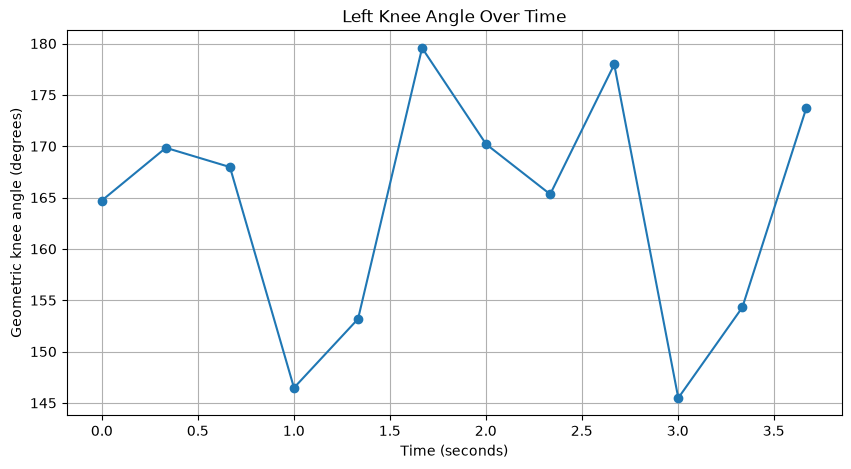

In [71]:
plt.figure(figsize=(10, 5))

plt.plot(
    knee_angle_times,
    knee_angles,
    marker="o"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Geometric knee angle (degrees)")
plt.title("Left Knee Angle Over Time")
plt.grid(True)

plt.show()

### 15. Investigating Sudden Changes in Knee Angle

#### Objective
Investigate abrupt changes in the estimated knee angle and determine whether they may reflect genuine movement or pose-estimation instability.

#### Method
We calculate the difference between consecutive angle estimates:
$$\Delta\theta_t = \theta_{t+1} - \theta_t$$

The sign indicates the direction of the change:
* Negative values indicate a decrease in the geometric knee angle.
* Positive values indicate an increase.
* Values near zero indicate relatively little change.

The magnitude, $|\Delta\theta_t|$, measures how large the change is, regardless of direction.

Large changes are not necessarily errors. They must be interpreted alongside the corresponding video frames, keypoint positions, and confidence scores.

In [72]:
angle_changes = np.diff(knee_angles)
time_intervals = np.diff(knee_angle_times)

print("Angle changes:")
print(angle_changes)

print("\nTime intervals:")
print(time_intervals)

Angle changes:
[  5.13322354  -1.87415501 -21.49749828   6.70800485  26.38361986
  -9.36893661  -4.87348438  12.63862508 -32.48002588   8.82521676
  19.43680803]

Time intervals:
[0.33366667 0.33366667 0.33366667 0.33366667 0.33366667 0.33366667
 0.33366667 0.33366667 0.33366667 0.33366667 0.33366667]


In [73]:
largest_angle_change_index = np.argmax(
    np.abs(angle_changes)
)

print(
    "Largest angle change:",
    angle_changes[largest_angle_change_index],
    "degrees"
)

print(
    "Time before:",
    knee_angle_times[largest_angle_change_index]
)

print(
    "Time after:",
    knee_angle_times[largest_angle_change_index + 1]
)

Largest angle change: -32.48002587684826 degrees
Time before: 2.6693333333360028
Time after: 3.003000000003003


### 15.4 — Visual Inspection of Sudden Angle Changes

We identified a decrease of approximately $32.48^\circ$ in the estimated left knee angle between $2.669$ and $3.003$ seconds.

To investigate this change, we will visualize the corresponding video frames and overlay the predicted left hip, knee, and ankle.

We will compare:
* The apparent position of the joints in the original video.
* The predicted keypoint coordinates.
* The confidence scores associated with each keypoint.
* The resulting geometric knee angles.

Visual inspection provides additional evidence for evaluating pose-estimation stability, although it does not establish ground-truth accuracy.

In [75]:
# Find the index of the largest change in knee angle
largest_angle_change_index = np.nanargmax(np.abs(angle_changes))

# Identify the positions before and after the change
before_position = largest_angle_change_index
after_position = largest_angle_change_index + 1

# Map these positions to the original video frame indices
before_frame_index = frame_indices[selected_positions[before_position]]
after_frame_index = frame_indices[selected_positions[after_position]]

print("Largest angle change:", angle_changes[largest_angle_change_index])
print("Time before:", knee_angle_times[before_position])
print("Time after:", knee_angle_times[after_position])
print("Frame before:", before_frame_index)
print("Frame after:", after_frame_index)

Largest angle change: -32.48002587684826
Time before: 2.6693333333360028
Time after: 3.003000000003003
Frame before: 80
Frame after: 90


In [76]:
def display_pose_frame(frame_index, keypoints, title):
    cap = cv2.VideoCapture(str(video_path))

    cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index))
    ret, frame = cap.read()

    cap.release()

    if not ret:
        raise RuntimeError(f"Could not read frame {frame_index}")

    # Convert the frame from BGR to RGB
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # Left hip, knee, and ankle
    joint_indices = [11, 13, 15]
    joint_names = ["Left hip", "Left knee", "Left ankle"]

    for joint_index, joint_name in zip(joint_indices, joint_names):
        y, x, confidence = keypoints[joint_index]

        # Convert normalized coordinates to pixel coordinates
        x_pixel = int(x * image_width)
        y_pixel = int(y * image_height)

        # Draw the predicted keypoint
        cv2.circle(
            frame_rgb,
            (x_pixel, y_pixel),
            8,
            (255, 0, 0),
            -1
        )

        # Label the point
        cv2.putText(
            frame_rgb,
            f"{joint_name}: {confidence:.2f}",
            (x_pixel + 10, y_pixel),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

    plt.figure(figsize=(6, 9))
    plt.imshow(frame_rgb)
    plt.title(title)
    plt.axis("off")
    plt.show()

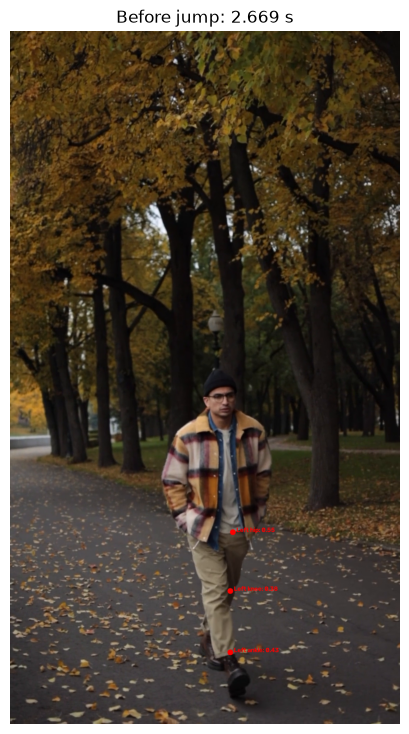

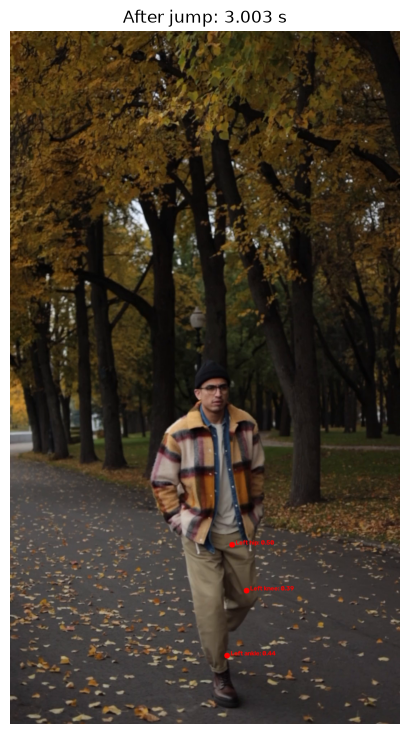

In [77]:
display_pose_frame(
    before_frame_index,
    all_keypoints[selected_positions[before_position]],
    f"Before jump: {knee_angle_times[before_position]:.3f} s"
)

display_pose_frame(
    after_frame_index,
    all_keypoints[selected_positions[after_position]],
    f"After jump: {knee_angle_times[after_position]:.3f} s"
)

### 15.5 — Identifying Anatomical Keypoint Misclassification

During visual inspection of the frames surrounding the largest knee-angle change, we observed that the predicted left hip was located on the person's right leg in the first frame. In the second frame, both the predicted left hip and left knee appeared to correspond to the person's right leg.

This suggests that the pose estimator may have incorrectly assigned anatomical keypoint labels in these frames.

Our knee-angle calculation uses the left hip, left knee, and left ankle. It assumes that all three keypoints correspond to the same anatomical leg. If this assumption is violated, the calculated angle may not represent the actual knee joint angle.

This observation illustrates an important limitation of markerless pose estimation: keypoint predictions may be anatomically inconsistent across frames, particularly when body parts overlap or are difficult to distinguish.

**Conclusion:** A mathematically correct angle calculation does not guarantee an anatomically valid measurement. Before interpreting joint angles, we must evaluate keypoint localization, anatomical consistency, and prediction confidence.

**Next step:** Investigate whether the predicted left and right hip, knee, and ankle keypoints remain anatomically consistent throughout the video.

### 16.1 — Visualizing Bilateral Lower-Limb Keypoints

**Objective**

Visualize the predicted left and right hips, knees, and ankles to investigate anatomical consistency.

**Method**

For each selected video frame, we will:
1. Retrieve the six lower-limb keypoints predicted by MoveNet.
2. Convert their normalized coordinates into image pixel coordinates.
3. Draw the predicted joints using different colors for the left and right sides.
4. Display the confidence score associated with each joint.

**Evaluation criteria**

We will visually examine whether:
- The predicted joints appear anatomically plausible.
- The left and right labels remain consistent between frames.
- Keypoints become unreliable when the legs overlap or are partially outside the image.
- Confidence scores provide useful information about prediction reliability.

**Limitation**

Visual inspection can reveal suspicious predictions, but it cannot establish exact anatomical accuracy. A reference annotation or suitable ground-truth measurement would be required for quantitative validation.

In [78]:
def display_both_legs(frame_index, keypoints, title):
    cap = cv2.VideoCapture(str(video_path))

    cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index))
    ret, frame = cap.read()

    cap.release()

    if not ret:
        raise RuntimeError(f"Could not read frame {frame_index}")

    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    joints = {
        "Left hip": 11,
        "Left knee": 13,
        "Left ankle": 15,
        "Right hip": 12,
        "Right knee": 14,
        "Right ankle": 16,
    }

    colors = {
        "Left hip": (255, 0, 0),
        "Left knee": (255, 0, 0),
        "Left ankle": (255, 0, 0),
        "Right hip": (0, 255, 0),
        "Right knee": (0, 255, 0),
        "Right ankle": (0, 255, 0),
    }

    for joint_name, joint_index in joints.items():
        y, x, confidence = keypoints[joint_index]

        x_pixel = int(x * image_width)
        y_pixel = int(y * image_height)

        color = colors[joint_name]

        cv2.circle(
            frame_rgb,
            (x_pixel, y_pixel),
            7,
            color,
            -1
        )

        label = f"{joint_name}: {confidence:.2f}"

        cv2.putText(
            frame_rgb,
            label,
            (x_pixel + 8, y_pixel),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            color,
            1
        )

    plt.figure(figsize=(8, 12))
    plt.imshow(frame_rgb)
    plt.title(title)
    plt.axis("off")
    plt.show()

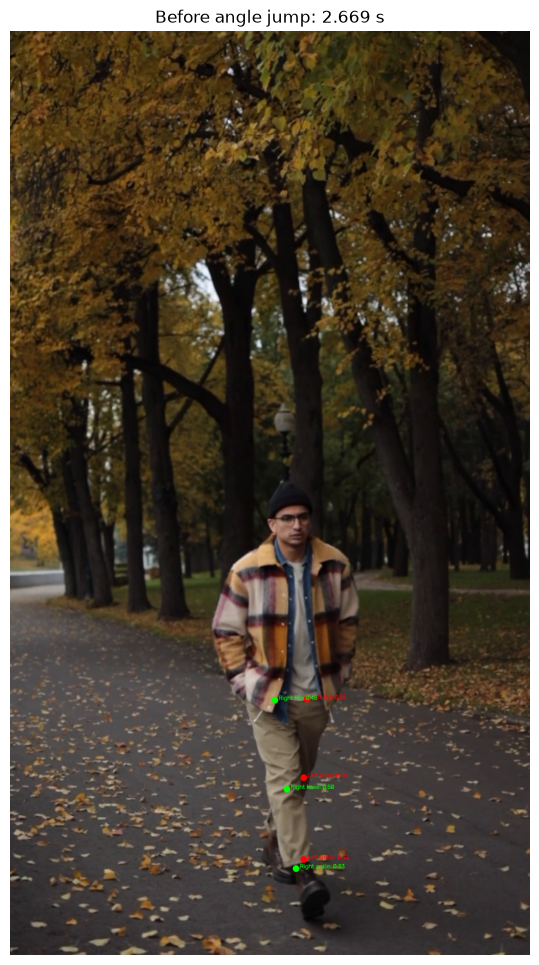

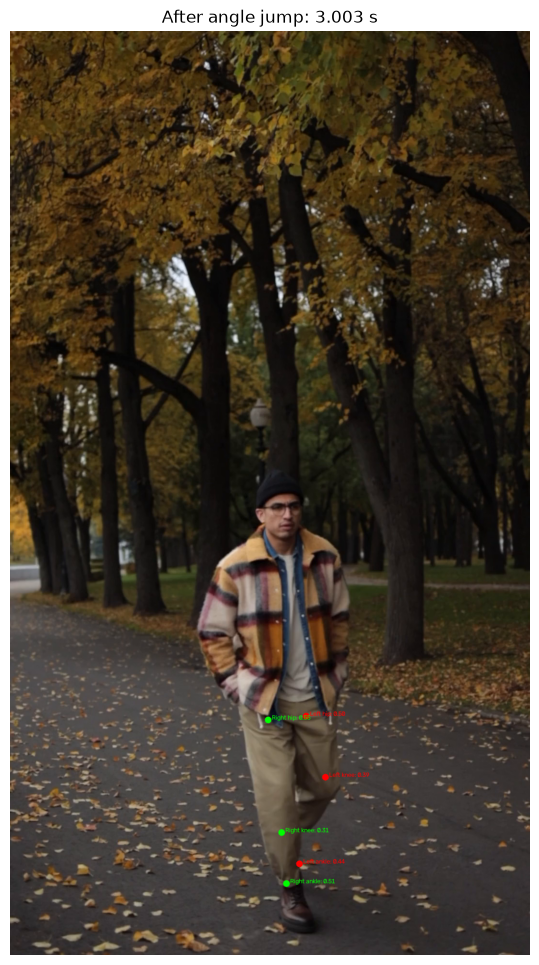

In [79]:
display_both_legs(
    before_frame_index,
    all_keypoints[selected_positions[before_position]],
    f"Before angle jump: {knee_angle_times[before_position]:.3f} s"
)

display_both_legs(
    after_frame_index,
    all_keypoints[selected_positions[after_position]],
    f"After angle jump: {knee_angle_times[after_position]:.3f} s"
)

### 16.2 — Observations on Keypoint Prediction Quality

After visually inspecting the frames before and after the largest knee-angle change, we observed that the predicted lower-limb keypoints were generally acceptable, although some minor localization errors were present.

MoveNet Lightning is designed for efficient, lightweight pose estimation. Its computational efficiency makes it useful for applications that require relatively fast inference, although its predictions may not always be sufficiently accurate for precise biomechanical measurements.

However, model size alone does not explain every prediction error. Other potential factors include:
- Partial occlusion of the legs.
- Changes in camera framing.
- Ambiguity between the left and right legs.
- Distortion introduced by resizing the original video to a square model input.
- The difficulty of estimating joints from a single RGB image.

**Conclusion:** The current predictions are suitable for learning and exploratory analysis, but we should not assume that they provide clinically or biomechanically accurate joint-angle measurements.

Further investigation is needed before using these estimates for quantitative gait analysis.

### 17.1 — Temporal Analysis of Lower-Limb Keypoint Confidence

**Objective**

Investigate how MoveNet's confidence scores for the hips, knees, and ankles vary across the video.

**Method**

For each sampled frame, we will extract the confidence scores of the six lower-limb keypoints and visualize them against time.

We will initially restrict the analysis to the first four seconds, when the lower limbs are more clearly visible.

**Questions**

- Which joints have the highest and lowest confidence?
- Do confidence scores change substantially between consecutive frames?
- Are low-confidence periods associated with occlusion or changes in camera framing?

**Limitation**

Confidence measures the model's estimated certainty, not the actual localization error. A high-confidence prediction can still be anatomically incorrect.

In [80]:
# Select the six lower-limb keypoints
joint_indices = {
    "Left hip": 11,
    "Right hip": 12,
    "Left knee": 13,
    "Right knee": 14,
    "Left ankle": 15,
    "Right ankle": 16,
}

# Keep only frames from the first four seconds
selected_positions = np.where(time_seconds <= 4.0)[0]

# Extract confidence scores for each joint
confidence_data = {}

for joint_name, joint_index in joint_indices.items():
    confidence_data[joint_name] = all_keypoints[
        selected_positions, joint_index, 2
    ]

# Display the number of selected frames
print("Selected frames:", len(selected_positions))

# Display the first five confidence scores for each joint
for joint_name, scores in confidence_data.items():
    print(f"{joint_name}: {scores[:5]}")

Selected frames: 12
Left hip: [0.51400006 0.37660584 0.49940434 0.4679176  0.51060575]
Right hip: [0.3686476  0.5163526  0.58067787 0.40291512 0.45746034]
Left knee: [0.46920127 0.38716272 0.35360813 0.38747603 0.41117522]
Right knee: [0.2686177  0.42705488 0.37362862 0.41625684 0.37922713]
Left ankle: [0.37253687 0.47330704 0.36684528 0.3294854  0.5372076 ]
Right ankle: [0.3023815  0.33654886 0.29881808 0.40414783 0.32792404]


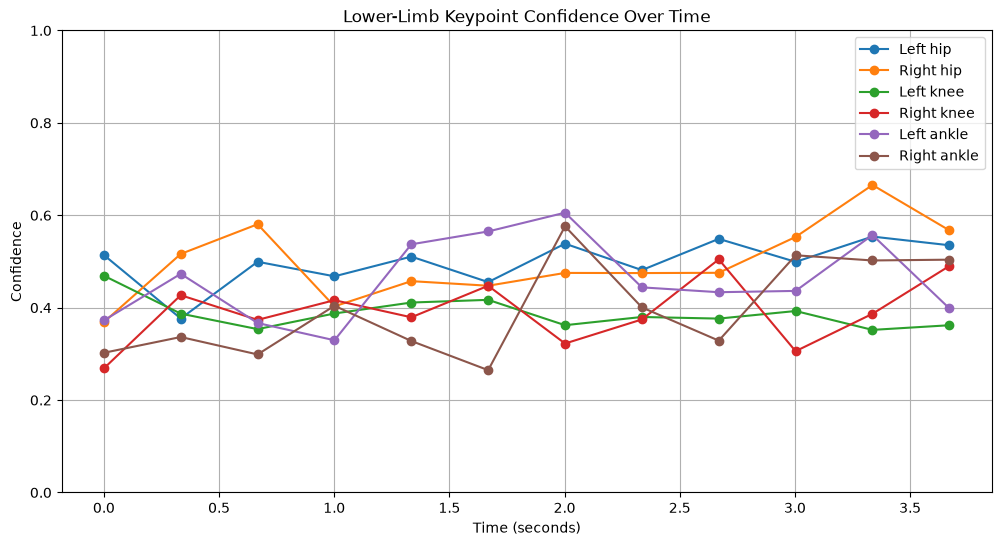

In [81]:
plt.figure(figsize=(12, 6))

for joint_name, scores in confidence_data.items():
    plt.plot(
        time_seconds[selected_positions],
        scores,
        marker="o",
        label=joint_name
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Confidence")
plt.title("Lower-Limb Keypoint Confidence Over Time")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

### 18.1 — Temporal Consistency of Lower-Limb Keypoints

#### Objective
Investigate how much the predicted positions of the hips, knees, and ankles change between consecutive sampled frames.

#### Method
For each joint, we calculate the Euclidean distance between its predicted positions in consecutive frames:
$$d_t = \sqrt{(x_{t+1} - x_t)^2 + (y_{t+1} - y_t)^2}$$

where:
* $(x_t, y_t)$ are the joint coordinates at time $t$.
* $(x_{t+1}, y_{t+1})$ are its coordinates in the next sampled frame.
* $d_t$ is the displacement in pixels.

We will calculate this distance for all six lower-limb keypoints during the first four seconds of the video.

#### Interpretation
A large displacement may indicate:
* Genuine movement by the person.
* An unstable keypoint prediction.
* A change in which anatomical location the model predicts.
* Other effects, such as occlusion or camera movement.

A small displacement does not necessarily mean the prediction is accurate. The model could consistently predict the wrong location.

#### Limitation
Our video is sampled approximately every $0.334$ seconds. Therefore, these measurements describe changes between sampled frames, not the complete motion between every original video frame.

Additionally, the original video was resized to a square input for inference. The resulting pixel-coordinate measurements are exploratory because the preprocessing may distort the apparent geometry.

> **Key Principle:** Temporal consistency and anatomical accuracy are different properties. We should investigate both.

In [82]:
# Select frames from the first four seconds
selected_positions = np.where(time_seconds <= 4.0)[0]

# Define the six lower-limb keypoints
joint_indices = {
    "Left hip": 11,
    "Right hip": 12,
    "Left knee": 13,
    "Right knee": 14,
    "Left ankle": 15,
    "Right ankle": 16,
}

# Store the displacement values for each joint
joint_displacements = {}

# Time associated with each displacement
displacement_times = time_seconds[selected_positions][1:]

for joint_name, joint_index in joint_indices.items():

    # Extract predictions for the selected frames
    keypoints = all_keypoints[selected_positions, joint_index, :]

    # Convert normalized [y, x] coordinates to pixel [x, y]
    x_pixels = keypoints[:, 1] * image_width
    y_pixels = keypoints[:, 0] * image_height

    positions = np.column_stack((x_pixels, y_pixels))

    # Calculate displacement between consecutive positions
    differences = np.diff(positions, axis=0)

    distances = np.linalg.norm(differences, axis=1)

    joint_displacements[joint_name] = distances

print("Number of selected frames:", len(selected_positions))
print("Number of displacement measurements:", len(displacement_times))

for joint_name, distances in joint_displacements.items():
    print(
        f"{joint_name}: "
        f"mean = {np.mean(distances):.2f} pixels, "
        f"maximum = {np.max(distances):.2f} pixels"
    )

Number of selected frames: 12
Number of displacement measurements: 11
Left hip: mean = 20.48 pixels, maximum = 52.43 pixels
Right hip: mean = 21.38 pixels, maximum = 57.12 pixels
Left knee: mean = 31.21 pixels, maximum = 45.07 pixels
Right knee: mean = 39.00 pixels, maximum = 130.95 pixels
Left ankle: mean = 30.25 pixels, maximum = 54.02 pixels
Right ankle: mean = 34.77 pixels, maximum = 60.61 pixels


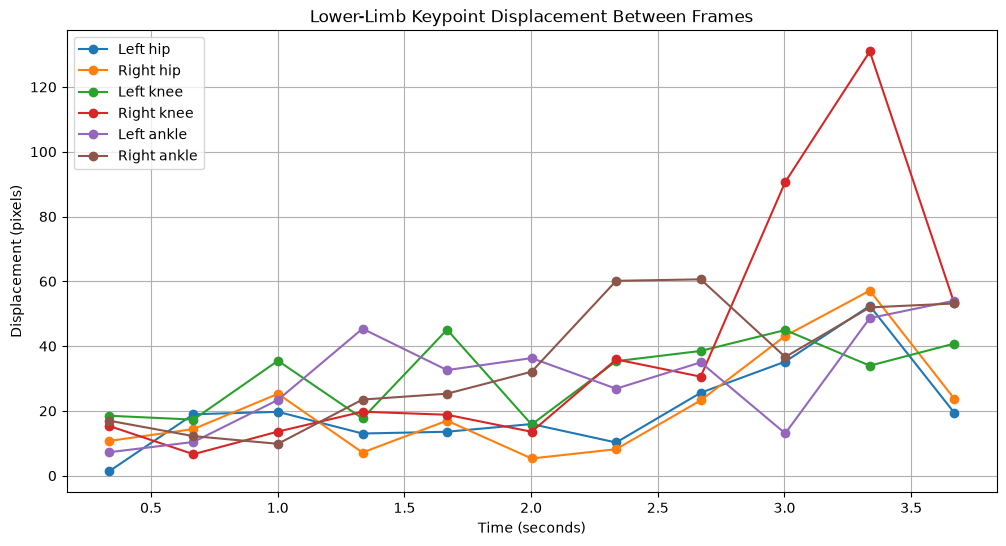

In [83]:
plt.figure(figsize=(12, 6))

for joint_name, distances in joint_displacements.items():
    plt.plot(
        displacement_times,
        distances,
        marker="o",
        label=joint_name
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Displacement (pixels)")
plt.title("Lower-Limb Keypoint Displacement Between Frames")
plt.legend()
plt.grid(True)
plt.show()

### 19.1 — Relationship Between Keypoint Confidence and Displacement

#### Objective
Investigate whether large changes in predicted joint positions are associated with lower keypoint confidence.

#### Method
For each lower-limb joint, we will compare:
* Its confidence score in consecutive sampled frames.
* Its displacement between those frames.

For each pair of consecutive frames, we will calculate the mean confidence of the two corresponding predictions:
$$C_t = \frac{c_t + c_{t+1}}{2}$$

where $c_t$ and $c_{t+1}$ are the confidence scores of the same joint in consecutive frames.

We will then compare this value with the measured displacement:
$$d_t = \sqrt{(x_{t+1} - x_t)^2 + (y_{t+1} - y_t)^2}$$

#### Interpretation
Large displacement combined with low confidence may indicate an unreliable prediction.

However:
* Large displacement with high confidence may represent genuine movement.
* Small displacement with high confidence does not prove anatomical accuracy.
* Small displacement with low confidence may indicate a consistently uncertain prediction.

#### Limitation
Camera motion can change the image coordinates of multiple joints simultaneously. Consequently, displacement is not a direct measurement of the person's movement relative to their body.

Confidence is also not a calibrated probability of anatomical correctness.

We will use these measurements as diagnostic signals, not as definitive rules for accepting or rejecting keypoints.

In [84]:
joint_mean_confidence = {}

for joint_name, joint_index in joint_indices.items():

    # Confidence values for the selected frames
    scores = all_keypoints[
        selected_positions, joint_index, 2
    ]

    # Mean confidence for each consecutive frame pair
    mean_scores = (scores[:-1] + scores[1:]) / 2

    joint_mean_confidence[joint_name] = mean_scores

print("Mean confidence values for consecutive frame pairs:\n")

for joint_name, scores in joint_mean_confidence.items():
    print(f"{joint_name}:")
    print(np.round(scores, 3))

Mean confidence values for consecutive frame pairs:

Left hip:
[0.445 0.438 0.484 0.489 0.483 0.497 0.51  0.515 0.524 0.527 0.545]
Right hip:
[0.443 0.549 0.492 0.43  0.453 0.461 0.475 0.475 0.514 0.609 0.617]
Left knee:
[0.428 0.37  0.371 0.399 0.414 0.39  0.371 0.378 0.385 0.372 0.357]
Right knee:
[0.348 0.4   0.395 0.398 0.413 0.385 0.349 0.44  0.405 0.346 0.439]
Left ankle:
[0.423 0.42  0.348 0.433 0.551 0.585 0.525 0.439 0.435 0.497 0.478]
Right ankle:
[0.319 0.318 0.351 0.366 0.296 0.42  0.488 0.365 0.421 0.508 0.503]


In [85]:
right_knee_displacement = joint_displacements["Right knee"]
right_knee_confidence = joint_mean_confidence["Right knee"]

largest_jump_index = np.argmax(right_knee_displacement)

print("Largest right-knee displacement:")
print(f"{right_knee_displacement[largest_jump_index]:.2f} pixels")

print("\nTime interval:")
print(
    f"{displacement_times[largest_jump_index]:.3f} s "
    f"to {displacement_times[largest_jump_index + 1]:.3f} s"
)

print("\nMean confidence across this frame pair:")
print(f"{right_knee_confidence[largest_jump_index]:.3f}")

Largest right-knee displacement:
130.95 pixels

Time interval:
3.337 s to 3.670 s

Mean confidence across this frame pair:
0.346


### 19.4 — Interpreting Displacement and Confidence Together

The largest observed displacement of the right knee was approximately 130.95 pixels between 3.337 and 3.670 seconds. The mean confidence across the two corresponding predictions was approximately 0.346.

This combination suggests that the right-knee prediction deserves further investigation.

However, the video contains camera movement, which can change the image coordinates of the joints independently of their movement relative to the person's body.

Consequently, we cannot determine from displacement and confidence alone whether this change resulted from genuine movement, camera motion, pose-estimation instability, or a combination of these factors.

**Conclusion:** Confidence and displacement are complementary diagnostic signals. Neither is sufficient by itself to establish the anatomical accuracy of a predicted joint.

### 20.4 Preserving the Aspect Ratio with Letterboxing

#### Objective
Prepare video frames for MoveNet while preserving the original image's aspect ratio. This also establishes the information needed to map predicted keypoints back to the original video coordinates.

---

#### 1. Why Is Letterboxing Necessary?
Our original video has a resolution of $1080 \times 1920$ pixels, whereas MoveNet expects a square input image, typically $192 \times 192$ pixels.

A straightforward resize operation changes the image's aspect ratio:

```python
resized_frame = cv2.resize(
    frame_rgb,
    (input_width, input_height)
)
```

This stretches or compresses the person in the image. Consequently, body proportions and joint geometry may be distorted.

Because our project focuses on estimating hip, knee, and ankle angles, preserving the original image geometry is important. Letterboxing solves this problem by resizing the image without changing its aspect ratio and filling the remaining space with padding.

---

#### 2. Calculate the Scale Factor
Let the original image dimensions be:
* $W_o$: original image width
* $H_o$: original image height

Let the model input dimensions be:
* $W_m$: model input width
* $H_m$: model input height

We calculate the scale factor as:
$$s = \min\left(\frac{W_m}{W_o}, \, \frac{H_m}{H_o}\right)$$

Taking the minimum ensures that the resized image fits entirely inside the model input dimensions.

The resized dimensions are:
$$W_r = \operatorname{round}(s W_o)$$
$$H_r = \operatorname{round}(s H_o)$$

This approach preserves the image's aspect ratio, apart from minor rounding effects.

---

#### 3. Calculate the Padding
After resizing, the image may not fill the entire model input. For centered padding, the amount added to the left and top is:
$$p_x = \left\lfloor\frac{W_m - W_r}{2}\right\rfloor$$
$$p_y = \left\lfloor\frac{H_m - H_r}{2}\right\rfloor$$

The remaining padding is added to the opposite sides. If the total padding is odd, the two sides may differ by one pixel.

The resized image is placed inside a blank canvas with dimensions $H_m \times W_m$.

---

#### 4. Example with Our Video
For an original image of $1080 \times 1920$ pixels and a model input of $192 \times 192$ pixels:
$$s = \min\left(\frac{192}{1080}, \, \frac{192}{1920}\right) = 0.1$$

The resized image dimensions become:
$$W_r = 1080 \times 0.1 = 108$$
$$H_r = 1920 \times 0.1 = 192$$

The horizontal padding is:
$$p_x = \frac{192 - 108}{2} = 42$$

There is no vertical padding ($p_y = 0$).

Therefore, the original image becomes a $108 \times 192$ image centered inside a $192 \times 192$ canvas, with $42$ pixels of padding on each horizontal side.

---

#### 5. Mapping Predicted Keypoints Back to the Original Image
MoveNet returns keypoints with normalized coordinates. In our current pipeline, each keypoint is represented as:
$$[y_n, \, x_n, \, c]$$

where:
* $y_n$: normalized vertical coordinate
* $x_n$: normalized horizontal coordinate
* $c$: model confidence score

Normalized coordinates are typically expressed relative to the model input dimensions.

First, convert the normalized coordinates to model-input pixel coordinates:
$$x_m = x_n W_m$$
$$y_m = y_n H_m$$

Next, remove the padding and reverse the resize operation:
$$\boxed{x_o = \frac{x_m - p_x}{s}}$$
$$\boxed{y_o = \frac{y_m - p_y}{s}}$$

Here, $x_o$ and $y_o$ are the estimated keypoint coordinates in the original image.

> **Important:** If a predicted keypoint falls inside the padding region, its mapped coordinates may lie outside the original image. Such a prediction must be handled carefully rather than automatically accepted as a valid body landmark.

---

#### 6. Why Does This Matter for Joint-Angle Estimation?
Our research direction involves estimating hip, knee, and ankle angles from walking videos.

If the image is distorted during preprocessing, the geometry of the pose can change. Letterboxing avoids this particular distortion.

However, letterboxing alone does not guarantee accurate anatomical angles. Other factors remain important:
* Pose-estimation errors and left/right keypoint swaps.
* Occlusion and low-confidence landmarks.
* Camera movement and perspective.
* Whether the subject is filmed in the sagittal plane.
* Correct mapping from model coordinates to original-image coordinates.

For our project, we should use the inverse transformation before calculating angles in original-image pixel coordinates.

---

#### 7. Important Implementation Note
Changing the preprocessing cell does not automatically update previously calculated keypoints.

To use letterboxing consistently, we must:
1. Apply the same preprocessing to every frame passed to MoveNet.
2. Run inference again on the newly prepared frames.
3. Map the predicted keypoints back to the original image coordinates.
4. Recalculate confidence, displacement, and joint angles using the corrected coordinates.

We should not directly compare the new angle estimates with our earlier estimates without considering that the preprocessing has changed.

> **Key Takeaway:** Letterboxing preserves the image's aspect ratio by resizing the image proportionally and padding the remaining space. Recording the scale factor and padding values allows us to reverse the transformation and recover keypoints in the original image coordinate system.